In [180]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.special import factorial
from scipy import stats
from scipy.optimize import curve_fit

ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

rng = np.random.default_rng(12)

In [181]:
dati = np.genfromtxt(
"dati.csv",
delimiter=",",
names=True
)
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]


In [182]:
if(len(x) == len(y) == len(sigma_y)):
    print("stessa dimensione")
else:
    print("errore")

for i in range(len(x)):
    if sigma_y[i] < 0:
        print("error")

max = y[0]
for i in y:
        if i >= max:
            max = i
print("il valore max della funzione è: ", max)
print("essendo ", max, " un valore finito, allora la funzione è finita\n")
print(len(x) ,"\n")
print(x, "\n")
print(y ,"\n")
print(sigma_y)


stessa dimensione
il valore max della funzione è:  451.0
essendo  451.0  un valore finito, allora la funzione è finita

161 

[-5.     -4.9375 -4.875  -4.8125 -4.75   -4.6875 -4.625  -4.5625 -4.5
 -4.4375 -4.375  -4.3125 -4.25   -4.1875 -4.125  -4.0625 -4.     -3.9375
 -3.875  -3.8125 -3.75   -3.6875 -3.625  -3.5625 -3.5    -3.4375 -3.375
 -3.3125 -3.25   -3.1875 -3.125  -3.0625 -3.     -2.9375 -2.875  -2.8125
 -2.75   -2.6875 -2.625  -2.5625 -2.5    -2.4375 -2.375  -2.3125 -2.25
 -2.1875 -2.125  -2.0625 -2.     -1.9375 -1.875  -1.8125 -1.75   -1.6875
 -1.625  -1.5625 -1.5    -1.4375 -1.375  -1.3125 -1.25   -1.1875 -1.125
 -1.0625 -1.     -0.9375 -0.875  -0.8125 -0.75   -0.6875 -0.625  -0.5625
 -0.5    -0.4375 -0.375  -0.3125 -0.25   -0.1875 -0.125  -0.0625  0.
  0.0625  0.125   0.1875  0.25    0.3125  0.375   0.4375  0.5     0.5625
  0.625   0.6875  0.75    0.8125  0.875   0.9375  1.      1.0625  1.125
  1.1875  1.25    1.3125  1.375   1.4375  1.5     1.5625  1.625   1.6875
  1.75    

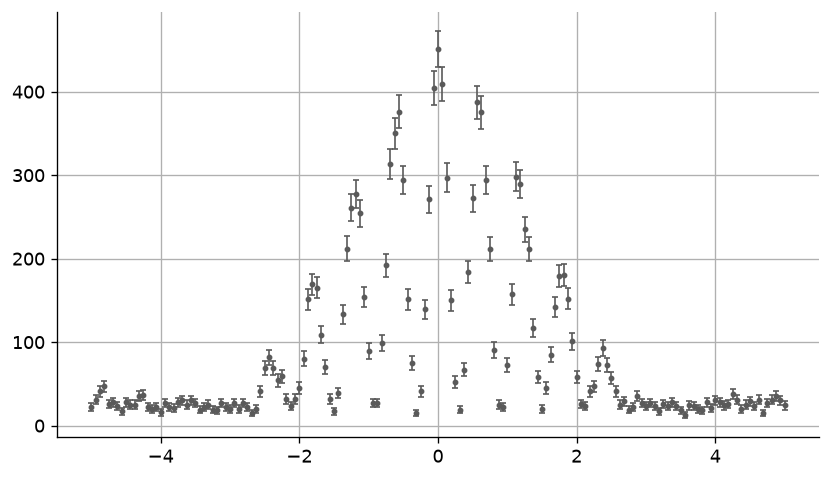

In [183]:
for i in y:
    if i < 1:
        err=1
    else: 
        err=np.sqrt(y)
fig, ax = plt.subplots()
ax.errorbar(
    x,
    y,
    yerr=sigma_y,
    fmt="o",
    linestyle="none",
    color=GRIGIO,
    markersize=2.5,
    capsize=2,
    elinewidth=1.0,
)
plt.grid()
plt.show()


In [184]:
y_est=[]
for i in range(len(x)):
    if np.abs(x[i])>=3:
        y_est.append(y[i])

y_est = np.array(y_est)

B_0 = np.median(y_est)
print(B_0)

I_0 = np.max(y) - B_0
print(I_0)

lower = [0.0, 0.0, 0.10, 1.0]
upper = [np.inf, np.inf, 3.0, 12.0]
print(lower)
print(upper)

print("abbiamo preso i valori esterni dove iniziavano ad essere simili")

25.0
426.0
[0.0, 0.0, 0.1, 1.0]
[inf, inf, 3.0, 12.0]
abbiamo preso i valori esterni dove iniziavano ad essere simili


[[ 2.55641568e-01 -6.84972384e-01  4.51109026e-04  3.69129896e-05]
 [-6.84972384e-01  2.55536934e+01  1.47662951e-02 -2.40123992e-04]
 [ 4.51109026e-04  1.47662951e-02  4.66275974e-05 -4.76315272e-07]
 [ 3.69129896e-05 -2.40123992e-04 -4.76315272e-07  3.37328124e-05]]


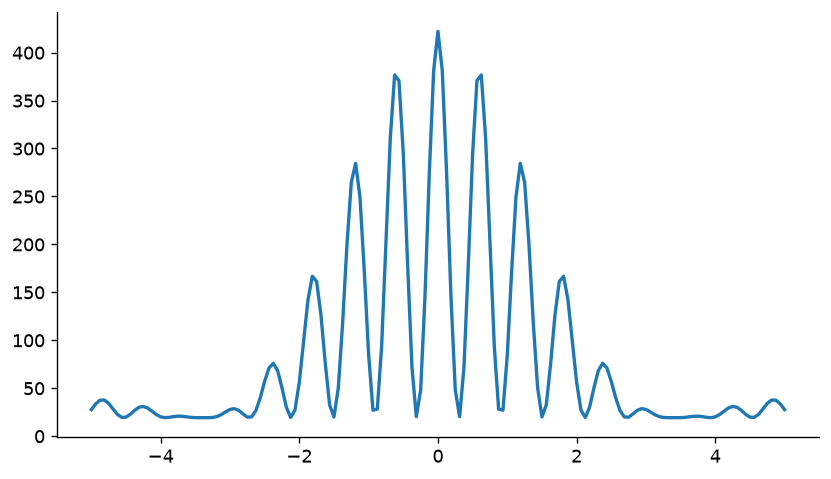

B  =  19.1839 +-  0.5056
I  =  403.0555 +-  5.0551
alfa  =  0.9094 +-  0.0068
delta  =  5.1952 +-  0.0058


In [185]:
def interference_function(x, B, I, alfa, delta):
    E = (np.sinc(alfa * x / np.pi))**2

    C = (np.cos(delta * x))**2

    return B + I * E * C


p0 = [
    B_0, 
    I_0,    
    1.5,
    3.
]

popt, pcov = curve_fit(
interference_function, x, y,
p0=p0,
sigma=sigma_y,
absolute_sigma=True,
bounds=(lower, upper),
maxfev=100000
)
parametri = ["B", "I", "alfa", "delta"]
y_fit = interference_function(x, *popt)
print(pcov)
plt.plot(x, y_fit, linewidth=2)
plt.show()

for i in range(4):
    print(parametri[i], " = ",round(popt[i],4) ,"+- ", round(np.sqrt(pcov[i][i]),4))

[[ 1.         -0.26799734  0.13066048  0.01257006]
 [-0.26799734  1.          0.42778267 -0.00817867]
 [ 0.13066048  0.42778267  1.         -0.0120101 ]
 [ 0.01257006 -0.00817867 -0.0120101   1.        ]]


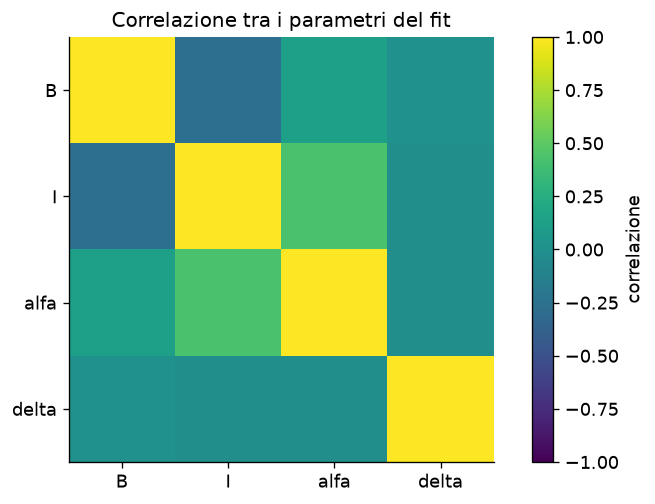

[[ 1.   -0.27  0.13  0.01]
 [-0.27  1.    0.43 -0.01]
 [ 0.13  0.43  1.   -0.01]
 [ 0.01 -0.01 -0.01  1.  ]]


In [186]:
p = np.zeros((len(popt),len(popt)))
for i in range(len(p0)):
    for j in range(len(p0)):
        p[i][j] = (pcov[i][j]) / np.sqrt((pcov[i][i]) * (pcov[j][j]))

print(p)

plt.imshow(p, vmin=-1, vmax=1)
plt.xticks(range(len(parametri)), parametri)
plt.yticks(range(len(parametri)), parametri)
plt.colorbar(label="correlazione")
plt.title("Correlazione tra i parametri del fit")
plt.show()

print(np.round(p, 2))

In [187]:
r = np.zeros(len(x))
ro = np.zeros(len(x))
chi_quadro = 0
for i in range(len(x)):
    r[i] = y[i] - y_fit[i]
    ro[i] = r[i] / sigma_y[i]

    chi_quadro += (ro[i])**2

v = len(x) - 4
chi_rid = chi_quadro / v
print(ro)
print(chi_quadro , v , chi_rid)

from scipy.stats import chi2
p_value = chi2.sf(chi_quadro, v)


[-1.18837550e+00 -4.55014125e-01  5.57174973e-01  1.36808241e+00
 -1.57883215e+00 -5.11198296e-02  6.29663498e-02 -6.09903453e-01
  1.56564833e+00  4.50712562e-01 -3.74670106e-01  8.34914071e-01
  8.47892497e-01 -1.54031472e+00 -1.32288013e+00 -9.45492248e-02
 -1.01040517e+00  1.50282801e+00  5.22163814e-01  1.48177723e-01
  1.36588894e+00  1.71208708e+00  9.86581017e-01  1.91501804e+00
  1.49615950e+00 -4.28647802e-02  5.97369530e-01  1.16251375e+00
 -9.56728274e-02 -5.62847774e-01  8.78648197e-01 -6.95042306e-01
 -1.74262259e+00 -3.10228504e-01 -1.53081879e+00  7.52559301e-01
  4.91364407e-01 -1.29850682e+00 -1.52149947e+00  1.21118055e-01
  1.44580808e+00  1.21383671e+00 -8.27537820e-01 -1.93458346e+00
  1.13405721e+00  3.11352519e-01  7.57316129e-01  8.53066006e-01
 -1.67663950e+00 -2.19028517e+00  7.18976475e-01  1.81522321e-01
  2.92727595e-01 -1.64756995e+00 -6.59099058e-01 -7.48402568e-02
 -7.17983468e-01 -1.81457695e+00  1.30154096e+00  8.20692201e-01
 -2.28709176e-01 -4.51884

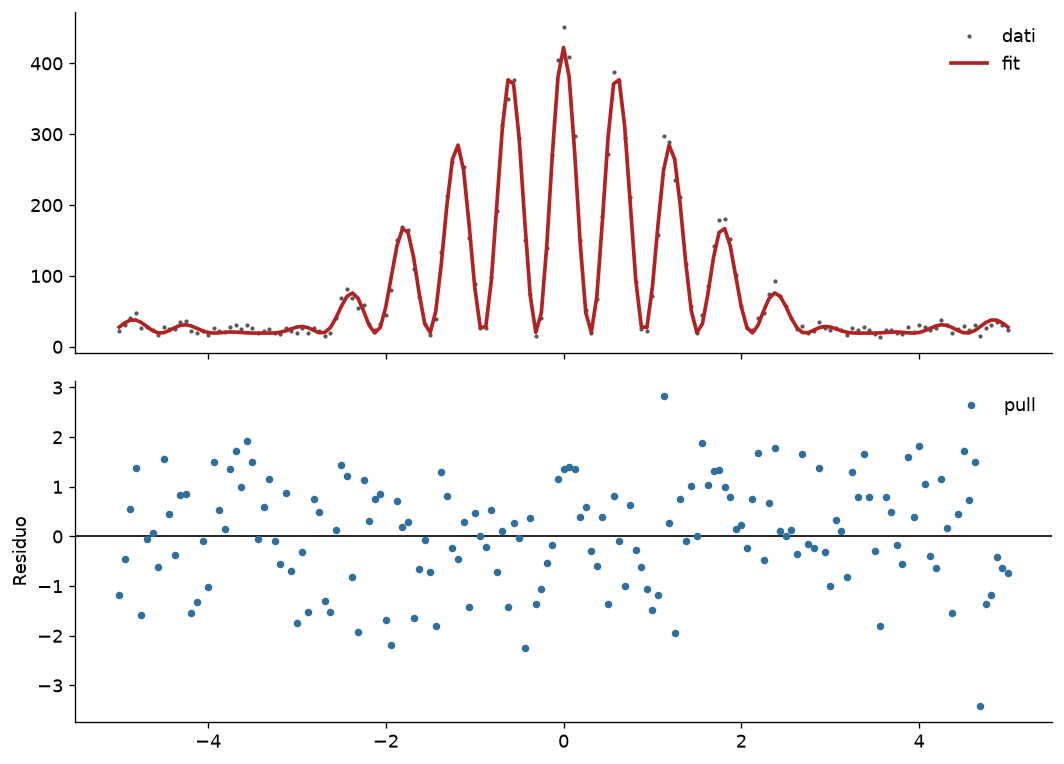

In [188]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 6.5))
axes[0].plot(x, y, ".", ms=3, color="0.35", label="dati")
axes[0].plot(x, y_fit, lw=2.2, color="firebrick", label="fit")


axes[0].legend()



axes[1].axhline(0.0, color="black", lw=1)

axes[1].set_ylabel(r"Residuo")
axes[1].plot(x , ro, ".", ms=7, color=AZZURRO, label="pull")
axes[1].legend()

plt.tight_layout()
plt.show()
